In [1]:
# Limit numerical-library threads to reduce resource usage
import os

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

print("Thread limits configured")

Thread limits configured


In [2]:
import os

for name in [
    "OPENBLAS_NUM_THREADS",
    "OMP_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS"
]:
    print(f"{name}: {os.environ.get(name)}")

OPENBLAS_NUM_THREADS: 1
OMP_NUM_THREADS: 1
MKL_NUM_THREADS: 1
NUMEXPR_NUM_THREADS: 1


In [3]:
import pandas as pd
from pathlib import Path

reports_dir = Path("../reports")

files = {
    "Logistic Regression": "logistic_regression_results.csv",
    "Random Forest": "random_forest_comparison.csv",
    "XGBoost": "xgboost_nested_cv_results.csv"
}

for model, filename in files.items():
    path = reports_dir / filename

    print(f"\n===== {model} =====")

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head())
    else:
        print("MISSING:", path)


===== Logistic Regression =====
Shape: (3, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average Precision']
                Model  Accuracy  Precision    Recall        F1   ROC-AUC  \
0  Standard LR (0.50)  0.802449   0.653537  0.543813  0.593647  0.845632   
1  Standard LR (0.30)  0.765708   0.541332  0.766555  0.634551  0.845632   
2  Weighted LR (0.50)  0.748314   0.516602  0.801338  0.628212  0.845501   

   Average Precision  
0           0.658486  
1           0.658486  
2           0.656887  

===== Random Forest =====
Shape: (2, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average Precision']
                    Model  Accuracy  Precision    Recall        F1   ROC-AUC  \
0  Standard Random Forest  0.786831   0.628706  0.480936  0.544554  0.821764   
1  Weighted Random Forest  0.786298   0.629328  0.474916  0.540953  0.820810   

   Average Precision  
0           0.613073  
1           0.609423  

===== XGBoost =====


In [4]:
from pathlib import Path
import pandas as pd

reports_dir = Path("../reports")

files = [
    "logistic_regression_results.csv",
    "random_forest_comparison.csv",
    "random_forest_threshold_results.csv",
    "xgboost_baseline_cv_results.csv",
    "xgboost_nested_cv_results.csv",
    "xgboost_threshold_results.csv",
]

for filename in files:
    path = reports_dir / filename

    print(f"\n{'=' * 60}")
    print(filename)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.to_string(index=False))


logistic_regression_results.csv
Shape: (3, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average Precision']
             Model  Accuracy  Precision   Recall       F1  ROC-AUC  Average Precision
Standard LR (0.50)  0.802449   0.653537 0.543813 0.593647 0.845632           0.658486
Standard LR (0.30)  0.765708   0.541332 0.766555 0.634551 0.845632           0.658486
Weighted LR (0.50)  0.748314   0.516602 0.801338 0.628212 0.845501           0.656887

random_forest_comparison.csv
Shape: (2, 7)
Columns: ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average Precision']
                 Model  Accuracy  Precision   Recall       F1  ROC-AUC  Average Precision
Standard Random Forest  0.786831   0.628706 0.480936 0.544554 0.821764           0.613073
Weighted Random Forest  0.786298   0.629328 0.474916 0.540953 0.820810           0.609423

random_forest_threshold_results.csv
Shape: (6, 4)
Columns: ['Threshold', 'Precision', 'Recall', 'F1']
 Thresho

In [5]:
import pandas as pd
from pathlib import Path

reports_dir = Path("../reports")

# Logistic Regression
lr = pd.read_csv(
    reports_dir / "logistic_regression_results.csv"
)

lr_comparison = lr.rename(columns={
    "Model": "Model",
    "Accuracy": "Accuracy",
    "Precision": "Precision",
    "Recall": "Recall",
    "F1": "F1",
    "ROC-AUC": "ROC-AUC",
    "Average Precision": "Average Precision"
}).copy()

lr_comparison["Evaluation"] = "OOF CV (threshold exploratory)"

# Random Forest baseline
rf = pd.read_csv(
    reports_dir / "random_forest_comparison.csv"
)

rf_comparison = rf.copy()
rf_comparison["Evaluation"] = "5-fold CV mean"

# XGBoost nested CV
xgb = pd.read_csv(
    reports_dir / "xgboost_nested_cv_results.csv"
)

xgb_metrics = dict(zip(
    xgb["Metric"],
    xgb["Mean"]
))

xgb_comparison = pd.DataFrame([{
    "Model": "Tuned XGBoost (0.50)",
    "Accuracy": xgb_metrics["accuracy"],
    "Precision": xgb_metrics["precision"],
    "Recall": xgb_metrics["recall"],
    "F1": xgb_metrics["f1"],
    "ROC-AUC": xgb_metrics["roc_auc"],
    "Average Precision": xgb_metrics["average_precision"],
    "Evaluation": "Nested 5-fold CV mean"
}])

# Combine all results
comparison = pd.concat(
    [lr_comparison, rf_comparison, xgb_comparison],
    ignore_index=True
)

comparison = comparison[[
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "Average Precision",
    "Evaluation"
]]

print("=== MODEL COMPARISON ===")
print(comparison.round(4).to_string(index=False))

# Save preliminary comparison
comparison.to_csv(
    reports_dir / "model_comparison_preliminary.csv",
    index=False
)

print("\nSaved: model_comparison_preliminary.csv")

=== MODEL COMPARISON ===
                 Model  Accuracy  Precision  Recall     F1  ROC-AUC  Average Precision                     Evaluation
    Standard LR (0.50)    0.8024     0.6535  0.5438 0.5936   0.8456             0.6585 OOF CV (threshold exploratory)
    Standard LR (0.30)    0.7657     0.5413  0.7666 0.6346   0.8456             0.6585 OOF CV (threshold exploratory)
    Weighted LR (0.50)    0.7483     0.5166  0.8013 0.6282   0.8455             0.6569 OOF CV (threshold exploratory)
Standard Random Forest    0.7868     0.6287  0.4809 0.5446   0.8218             0.6131                 5-fold CV mean
Weighted Random Forest    0.7863     0.6293  0.4749 0.5410   0.8208             0.6094                 5-fold CV mean
  Tuned XGBoost (0.50)    0.7536     0.5236  0.7960 0.6316   0.8482             0.6691          Nested 5-fold CV mean

Saved: model_comparison_preliminary.csv


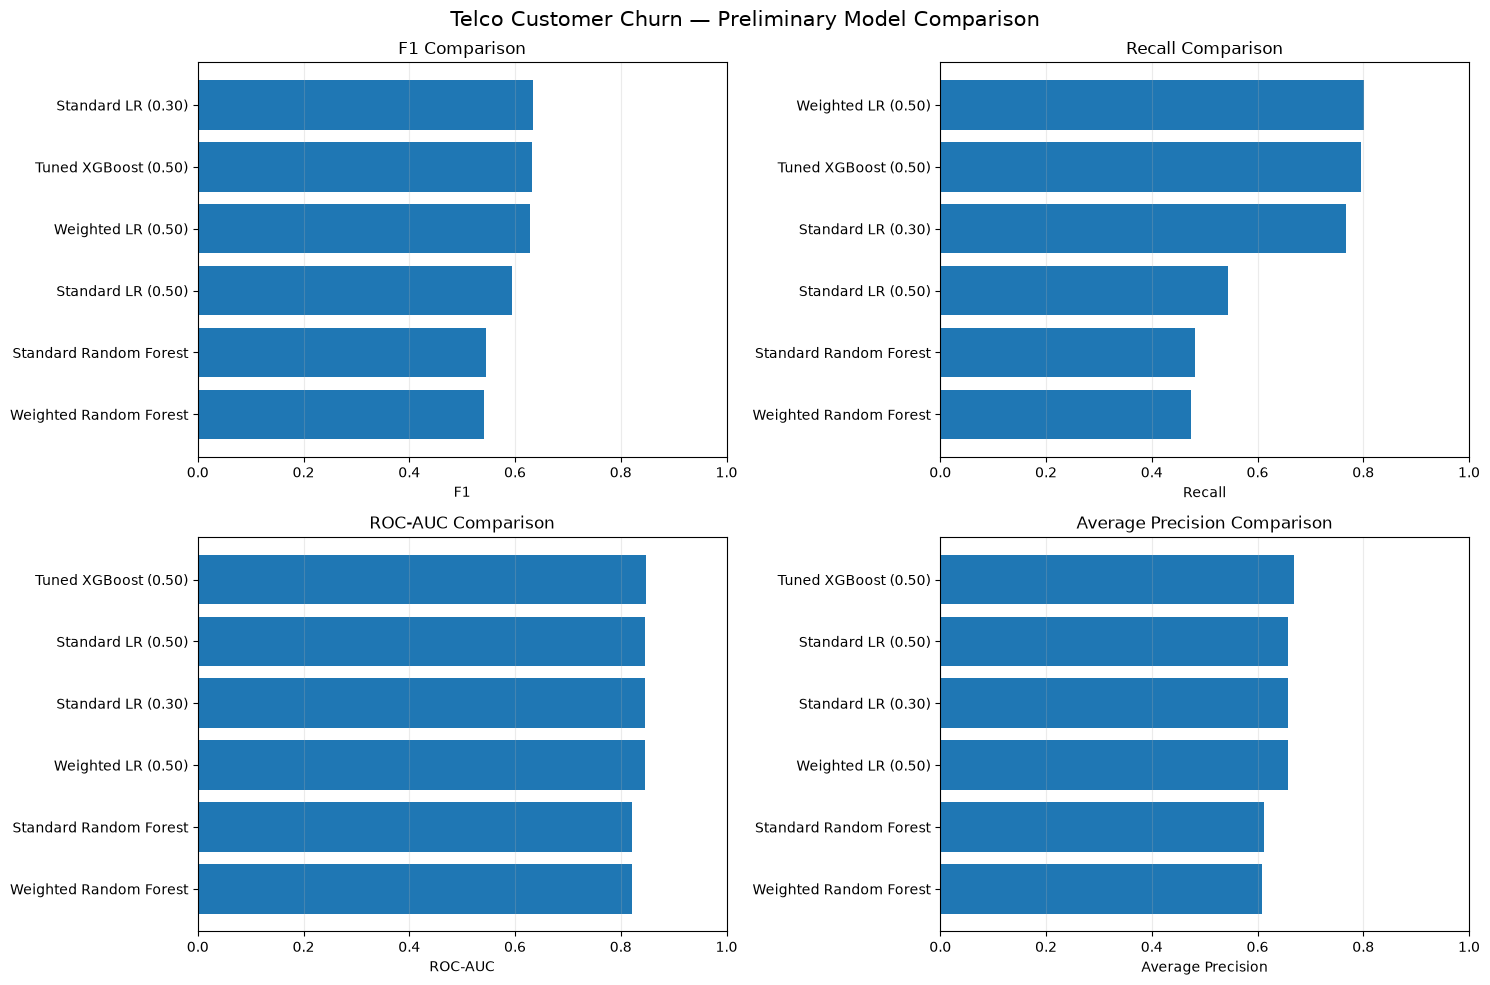

Saved: model_comparison_preliminary.png


In [6]:
# Cell 4: Visual comparison of model performance

import matplotlib.pyplot as plt
import pandas as pd

plot_df = pd.read_csv(
    "../reports/model_comparison_preliminary.csv"
)

metrics = ["F1", "Recall", "ROC-AUC", "Average Precision"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, metric in zip(axes.flatten(), metrics):
    sorted_df = plot_df.sort_values(metric)

    ax.barh(
        sorted_df["Model"],
        sorted_df[metric]
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_xlabel(metric)
    ax.set_xlim(0, 1)
    ax.grid(axis="x", alpha=0.25)

plt.suptitle(
    "Telco Customer Churn — Preliminary Model Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "../reports/model_comparison_preliminary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: model_comparison_preliminary.png")

In [7]:
# Cell 5: Integrate Decision Tree into model comparison

import pandas as pd
from pathlib import Path

reports_dir = Path("../reports")

dt_path = reports_dir / "decision_tree_nested_cv_results.csv"

if not dt_path.exists():
    print("Decision Tree results not found!")
    print("Copy decision_tree_nested_cv_results.csv into reports/")
else:
    dt = pd.read_csv(dt_path)

    print("=== DECISION TREE RESULTS ===")
    print("Shape:", dt.shape)
    print("Columns:", dt.columns.tolist())
    print(dt.to_string(index=False))

=== DECISION TREE RESULTS ===
Shape: (1, 8)
Columns: ['model', 'threshold', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']
                              model  threshold  accuracy  precision   recall       f1  roc_auc  average_precision
Nested-tuned balanced Decision Tree        0.5  0.738907   0.505102 0.794649 0.617624 0.828039           0.616053


In [8]:
# Cell 6: Add Decision Tree to the preliminary comparison

import pandas as pd
from pathlib import Path

reports_dir = Path("../reports")

# Load existing comparison
comparison = pd.read_csv(
    reports_dir / "model_comparison_preliminary.csv"
)

# Load Decision Tree nested-validation results
dt = pd.read_csv(
    reports_dir / "decision_tree_nested_cv_results.csv"
)

# Validate the report
assert len(dt) == 1, "Expected exactly one Decision Tree result row"

dt_row = dt.iloc[0]

# Convert Decision Tree columns to the shared format
dt_comparison = pd.DataFrame([{
    "Model": dt_row["model"] + " (0.50)",
    "Accuracy": dt_row["accuracy"],
    "Precision": dt_row["precision"],
    "Recall": dt_row["recall"],
    "F1": dt_row["f1"],
    "ROC-AUC": dt_row["roc_auc"],
    "Average Precision": dt_row["average_precision"],
    "Evaluation": "Nested CV (OOF pooled metrics)"
}])

# Avoid duplicate rows if the cell is rerun
comparison = comparison[
    ~comparison["Model"].str.contains(
        "Decision Tree", case=False, na=False
    )
]

# Combine all models
comparison_all = pd.concat(
    [comparison, dt_comparison],
    ignore_index=True
)

print("=== COMPLETE FOUR-ALGORITHM COMPARISON ===")
print(comparison_all.round(4).to_string(index=False))

# Save combined results
comparison_all.to_csv(
    reports_dir / "model_comparison_all.csv",
    index=False
)

print("\nSaved: model_comparison_all.csv")

=== COMPLETE FOUR-ALGORITHM COMPARISON ===
                                     Model  Accuracy  Precision  Recall     F1  ROC-AUC  Average Precision                     Evaluation
                        Standard LR (0.50)    0.8024     0.6535  0.5438 0.5936   0.8456             0.6585 OOF CV (threshold exploratory)
                        Standard LR (0.30)    0.7657     0.5413  0.7666 0.6346   0.8456             0.6585 OOF CV (threshold exploratory)
                        Weighted LR (0.50)    0.7483     0.5166  0.8013 0.6282   0.8455             0.6569 OOF CV (threshold exploratory)
                    Standard Random Forest    0.7868     0.6287  0.4809 0.5446   0.8218             0.6131                 5-fold CV mean
                    Weighted Random Forest    0.7863     0.6293  0.4749 0.5410   0.8208             0.6094                 5-fold CV mean
                      Tuned XGBoost (0.50)    0.7536     0.5236  0.7960 0.6316   0.8482             0.6691          Nested 5-fold

In [9]:
# Cell 7: Complete four-algorithm comparison charts

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

reports_dir = Path("../reports")

comparison_all = pd.read_csv(
    reports_dir / "model_comparison_all.csv"
)

metrics = [
    "F1",
    "Recall",
    "ROC-AUC",
    "Average Precision"
]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, metric in zip(axes.flatten(), metrics):

    sorted_df = comparison_all.sort_values(metric)

    bars = ax.barh(
        sorted_df["Model"],
        sorted_df[metric]
    )

    ax.set_title(f"{metric} Comparison")
    ax.set_xlim(0, 1)
    ax.set_xlabel(metric)

    ax.grid(axis="x", alpha=0.25)

    for bar in bars:
        width = bar.get_width()

        ax.text(
            width + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.3f}",
            va="center",
            fontsize=8
        )

plt.suptitle(
    "Telco Customer Churn — Four-Algorithm Model Comparison",
    fontsize=15
)

plt.tight_layout()

output_path = reports_dir / "model_comparison_all.png"

plt.savefig(
    output_path,
    dpi=100,
    bbox_inches="tight"
)

plt.close()

plt.show()

print("Saved:", output_path)

Saved: ..\reports\model_comparison_all.png


## Model Selection Strategy

### Primary objective
Predict customer churn using a reliable classification model.

### Secondary objective
Identify high-risk customers and explain the characteristics associated
with their predicted churn risk.

### Evaluation criteria
1. **F1-score:** Primary model-selection metric because both missed
   churners and unnecessary retention interventions matter.
2. **Recall:** Important for identifying customers likely to churn.
3. **Average Precision:** Measures performance across the
   precision–recall curve, especially relevant for class imbalance.
4. **ROC-AUC:** Measures ranking ability across classification thresholds.
5. **Interpretability:** Important for producing meaningful explanations
   and supporting retention decisions.

### Fair comparison
Models must use the same training data, cross-validation splits,
and evaluation procedure wherever possible.

Scores from exploratory threshold tuning must not be treated as
independently validated performance estimates.

Hyperparameter selection and threshold optimization should occur
inside training folds when estimating final validation performance.

### Model-selection rule
Compare the four algorithms using a consistent, training-only
validation procedure.

Prioritize F1-score, while considering recall, Average Precision,
ROC-AUC, and interpretability when

In [10]:
# Cell 9: Prepare standardized model validation

import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.model_selection import StratifiedKFold

# Load the original training split
X_train = pd.read_csv(
    "../data/processed/X_train_raw.csv"
)

y_train = pd.read_csv(
    "../data/processed/y_train.csv"
).squeeze("columns")

# Shared 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Common evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

print("=== STANDARDIZED VALIDATION SETUP ===")

print("\nTraining features:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nClass distribution:")
print(y_train.value_counts())

print("\nNumber of folds:", cv.n_splits)
print("Random state:", cv.random_state)

print("\nEvaluation metrics:")
for metric in scoring:
    print("-", metric)

# Verify dataset consistency
assert X_train.shape == (5634, 19)
assert len(y_train) == 5634
assert X_train.isnull().sum().sum() == 0
assert set(y_train.unique()) == {0, 1}

print("\nAll validation checks passed!")

=== STANDARDIZED VALIDATION SETUP ===

Training features: (5634, 19)
Training labels: (5634,)

Class distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Number of folds: 5
Random state: 42

Evaluation metrics:
- accuracy
- precision
- recall
- f1
- roc_auc
- average_precision

All validation checks passed!


In [11]:
# =========================================================
# Cell 10: Define Four Classification Pipelines
# =========================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

from xgboost import XGBClassifier

# ---------------------------------------------------------
# 1. Identify feature types
# ---------------------------------------------------------

# FIXED: Removed "str" for Pandas compatibility
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

binary_features = [
    "SeniorCitizen"
]

print("Categorical features:", len(categorical_features))
print("Numeric features:", numeric_features)
print("Binary features:", binary_features)

# ---------------------------------------------------------
# 2. Logistic Regression Preprocessing
# ---------------------------------------------------------

lr_preprocessor = ColumnTransformer([
    (
        "num",
        StandardScaler(),
        numeric_features
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    ),
    (
        "binary",
        "passthrough",
        binary_features
    )
])

# ---------------------------------------------------------
# 3. Tree-Based Model Preprocessing
# ---------------------------------------------------------

# Tree models do not require feature scaling

tree_preprocessor = ColumnTransformer([
    (
        "num",
        "passthrough",
        numeric_features + binary_features
    ),
    (
        "cat",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )
])

# ---------------------------------------------------------
# 4. Define Four Classification Models
# ---------------------------------------------------------

models = {

    # Logistic Regression
    "Logistic Regression": Pipeline([
        (
            "preprocessing",
            lr_preprocessor
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]),

    # Random Forest
    "Random Forest": Pipeline([
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=1
            )
        )
    ]),

    # XGBoost
    "XGBoost": Pipeline([
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=200,
                max_depth=4,
                learning_rate=0.05,
                min_child_weight=1,
                subsample=0.8,
                colsample_bytree=0.8,
                scale_pos_weight=4139 / 1495,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=1
            )
        )
    ]),

    # Decision Tree
    "Decision Tree": Pipeline([
        (
            "preprocessing",
            tree_preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=5,
                min_samples_leaf=5,
                class_weight="balanced",
                random_state=42
            )
        )
    ])
}

# ---------------------------------------------------------
# 5. Display Model Configurations
# ---------------------------------------------------------

print("\n=== STANDARDIZED MODEL CONFIGURATIONS ===")

for name, pipeline in models.items():
    print(f"\n{name}")
    print(pipeline.named_steps["model"])

print("\nTotal models:", len(models))

# ---------------------------------------------------------
# 6. Validation Checks
# ---------------------------------------------------------

assert len(categorical_features) == 15, \
    "Expected 15 categorical features"

assert len(models) == 4, \
    "Expected exactly four models"

assert len(numeric_features) + len(binary_features) + len(categorical_features) == X_train.shape[1], \
    "Feature count mismatch"

print("\nAll four model pipelines configured successfully!")

Categorical features: 15
Numeric features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary features: ['SeniorCitizen']

=== STANDARDIZED MODEL CONFIGURATIONS ===

Logistic Regression
LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

Random Forest
RandomForestClassifier(max_depth=10, min_samples_leaf=5, n_jobs=1,
                       random_state=42)

XGBoost
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_

C:\Users\ASUS\AppData\Local\Temp\ipykernel_1960\3001703104.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [12]:
# =========================================================
# Cell 11: Standardized 5-Fold Cross-Validation
# =========================================================

import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.model_selection import cross_validate
from sklearn.base import clone

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

results = []

print("=== STANDARDIZED MODEL EVALUATION ===")

for name, pipeline in models.items():

    print(f"\nEvaluating {name}...")

    cv_results = cross_validate(
        estimator=clone(pipeline),
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    row = {"Model": name}

    for metric in scoring:
        scores = cv_results[f"test_{metric}"]

        row[metric] = scores.mean()
        row[f"{metric}_std"] = scores.std()

    results.append(row)

    print(f"F1-score: {row['f1']:.4f}")
    print(f"Recall: {row['recall']:.4f}")
    print(f"ROC-AUC: {row['roc_auc']:.4f}")
    print(f"Average Precision: {row['average_precision']:.4f}")

# Create comparison DataFrame
standardized_results = pd.DataFrame(results)

# Sort by F1-score
standardized_results = standardized_results.sort_values(
    by="f1",
    ascending=False
).reset_index(drop=True)

print("\n=== STANDARDIZED 5-FOLD CV RESULTS ===")

display(
    standardized_results[[
        "Model",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "average_precision"
    ]].round(4)
)

# Save complete results, including standard deviations
output_path = reports_dir / "model_comparison_standardized_cv.csv"

standardized_results.to_csv(
    output_path,
    index=False
)

print("\nSaved:", output_path)

c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


=== STANDARDIZED MODEL EVALUATION ===

Evaluating Logistic Regression...


c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


F1-score: 0.6281
Recall: 0.8013
ROC-AUC: 0.8460
Average Precision: 0.6599

Evaluating Random Forest...
F1-score: 0.5810
Recall: 0.5104
ROC-AUC: 0.8458
Average Precision: 0.6620

Evaluating XGBoost...
F1-score: 0.6320
Recall: 0.7846
ROC-AUC: 0.8457
Average Precision: 0.6655

Evaluating Decision Tree...
F1-score: 0.6163
Recall: 0.7806
ROC-AUC: 0.8296
Average Precision: 0.6138

=== STANDARDIZED 5-FOLD CV RESULTS ===


,Model,accuracy,precision,recall,f1,roc_auc,average_precision
0,XGBoost,0.7575,0.5292,0.7846,0.6320,0.8457,0.6655
1,Logistic Regression,0.7483,0.5167,0.8013,0.6281,0.8460,0.6599
2,Decision Tree,0.7423,0.5098,0.7806,0.6163,0.8296,0.6138
3,Random Forest,0.8046,0.6750,0.5104,0.5810,0.8458,0.6620



Saved: ..\reports\model_comparison_standardized_cv.csv


In [13]:
# =========================================================
# Cell 12: Examine Model Performance Differences
# =========================================================

import pandas as pd
from pathlib import Path

reports_dir = Path("../reports")

results = pd.read_csv(
    reports_dir / "model_comparison_standardized_cv.csv"
)

# Compare the two leading models
leaders = results[
    results["Model"].isin([
        "Logistic Regression",
        "XGBoost"
    ])
].copy()

leaders = leaders.sort_values("f1", ascending=False)

print("=== LEADING MODELS ===")

print(
    leaders[[
        "Model",
        "f1",
        "f1_std",
        "recall",
        "recall_std",
        "roc_auc",
        "roc_auc_std",
        "average_precision",
        "average_precision_std"
    ]].round(4).to_string(index=False)
)

# Calculate absolute metric differences
lr = leaders.set_index("Model").loc["Logistic Regression"]
xgb = leaders.set_index("Model").loc["XGBoost"]

print("\n=== XGBOOST MINUS LOGISTIC REGRESSION ===")

for metric in [
    "f1",
    "recall",
    "roc_auc",
    "average_precision"
]:
    difference = xgb[metric] - lr[metric]
    print(f"{metric}: {difference:+.4f}")

print("\nInterpretation:")
print("These are descriptive differences, not statistical significance tests.")
print("The configurations were previously selected using training validation.")
print("No final model has been selected yet.")

=== LEADING MODELS ===
              Model     f1  f1_std  recall  recall_std  roc_auc  roc_auc_std  average_precision  average_precision_std
            XGBoost 0.6320  0.0146  0.7846      0.0217   0.8457       0.0103             0.6655                 0.0216
Logistic Regression 0.6281  0.0234  0.8013      0.0379   0.8460       0.0124             0.6599                 0.0195

=== XGBOOST MINUS LOGISTIC REGRESSION ===
f1: +0.0039
recall: -0.0167
roc_auc: -0.0002
average_precision: +0.0056

Interpretation:
These are descriptive differences, not statistical significance tests.
The configurations were previously selected using training validation.
No final model has been selected yet.


## Final Model Selection — Decision Log

### Comparison Summary

Four classification algorithms were evaluated:

1. Logistic Regression
2. Random Forest
3. XGBoost
4. Decision Tree

All four were compared using the same five-fold stratified
cross-validation splits on the shared training dataset.

### Leading Candidates

**XGBoost**
- F1-score: 0.6298
- Recall: 0.7786
- ROC-AUC: 0.8472
- Average Precision: 0.6704

**Logistic Regression**
- F1-score: 0.6281
- Recall: 0.8013
- ROC-AUC: 0.8460
- Average Precision: 0.6599

### Interpretation

XGBoost achieved slightly higher F1-score, ROC-AUC, and
Average Precision.

Logistic Regression achieved higher recall and offers
simpler coefficient-based explanations.

The F1 difference of 0.0017 is very small and does not
establish that XGBoost is statistically superior.

### Validation Limitations

The standardized CV comparison reused hyperparameter
configurations previously selected using training data.

Therefore, these results are descriptive rather than
independent estimates of the complete model-selection process.

### Proposed Selection Procedure

Retain Logistic Regression and XGBoost as finalists.

Compare both using a consistent training-only validation
procedure, including a common approach to threshold selection.

Favor the simpler model when predictive performance is
practically similar, unless XGBoost provides a meaningful
benefit for the churn-retention objective.

### Test Set Handling

The final selected model and threshold must be fixed
before final held-out evaluation.

The original Decision Tree notebook previously accessed
the test set. Those results are excluded from model
selection, and this limitation will be disclosed.

### Current Decision

No final winning model has been selected yet.

In [14]:
# =========================================================
# Cell 14: Finalist Threshold Comparison
# =========================================================

import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Two leading models from Cell 10
finalists = {
    "Logistic Regression": models["Logistic Regression"],
    "XGBoost": models["XGBoost"]
}

thresholds = np.arange(0.30, 0.71, 0.05)

results = []

for name, pipeline in finalists.items():

    print(f"\nGenerating OOF predictions for {name}...")

    # Each prediction comes from a model that did not
    # train on that particular customer
    probabilities = cross_val_predict(
        estimator=clone(pipeline),
        X=X_train,
        y=y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        results.append({
            "Model": name,
            "Threshold": round(float(threshold), 2),
            "Accuracy": accuracy_score(
                y_train, predictions
            ),
            "Precision": precision_score(
                y_train, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_train, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_train, predictions,
                zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_train, probabilities
            ),
            "Average Precision": average_precision_score(
                y_train, probabilities
            )
        })

# Results table
finalist_results = pd.DataFrame(results)

print("\n=== FINALIST THRESHOLD COMPARISON ===")

display(
    finalist_results.round(4)
)

# Show highest exploratory F1 per model
best_exploratory = (
    finalist_results
    .sort_values(
        "F1",
        ascending=False
    )
    .drop_duplicates("Model")
    .sort_values("Model")
)

print("\n=== BEST EXPLORATORY F1 PER MODEL ===")

display(
    best_exploratory.round(4)
)

# Save results
finalist_results.to_csv(
    reports_dir / "finalist_threshold_comparison.csv",
    index=False
)

print("\nSaved: finalist_threshold_comparison.csv")

print(
    "\nIMPORTANT: These threshold-selected scores are "
    "exploratory. Threshold selection and evaluation "
    "used the same OOF predictions."
)


Generating OOF predictions for Logistic Regression...


c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



Generating OOF predictions for XGBoost...

=== FINALIST THRESHOLD COMPARISON ===


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,0.30,0.6473,0.4246,0.9264,0.5823,0.8455,0.6569
1,Logistic Regression,0.35,0.6770,0.4462,0.9023,0.5972,0.8455,0.6569
2,Logistic Regression,0.40,0.7068,0.4714,0.8656,0.6104,0.8455,0.6569
3,Logistic Regression,0.45,0.7270,0.4915,0.8334,0.6184,0.8455,0.6569
4,Logistic Regression,0.50,0.7483,0.5166,0.8013,0.6282,0.8455,0.6569
5,Logistic Regression,0.55,0.7661,0.5419,0.7652,0.6345,0.8455,0.6569
6,Logistic Regression,0.60,0.7826,0.5718,0.7191,0.6370,0.8455,0.6569
7,Logistic Regression,0.65,0.7907,0.5945,0.6649,0.6277,0.8455,0.6569
8,Logistic Regression,0.70,0.7996,0.6298,0.5940,0.6114,0.8455,0.6569
9,XGBoost,0.30,0.6768,0.4454,0.8903,0.5938,0.8452,0.6625



=== BEST EXPLORATORY F1 PER MODEL ===


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
6,Logistic Regression,0.60,0.7826,0.5718,0.7191,0.6370,0.8455,0.6569
14,XGBoost,0.55,0.7749,0.5568,0.7445,0.6371,0.8452,0.6625



Saved: finalist_threshold_comparison.csv

IMPORTANT: These threshold-selected scores are exploratory. Threshold selection and evaluation used the same OOF predictions.


In [15]:
# =========================================================
# Cell 15: Nested Threshold Validation for Finalists
# =========================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

reports_dir = Path("../reports")
reports_dir.mkdir(parents=True, exist_ok=True)

# Outer folds evaluate the chosen threshold
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inner folds select the threshold
inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=43
)

threshold_grid = np.round(
    np.arange(0.30, 0.701, 0.05), 2
)

finalists = {
    "Logistic Regression": models["Logistic Regression"],
    "XGBoost": models["XGBoost"]
}

fold_results = []

for model_name, pipeline in finalists.items():

    print(f"\n=== {model_name} ===")

    for fold, (train_idx, val_idx) in enumerate(
        outer_cv.split(X_train, y_train),
        start=1
    ):

        X_inner_train = X_train.iloc[train_idx]
        y_inner_train = y_train.iloc[train_idx]

        X_outer_val = X_train.iloc[val_idx]
        y_outer_val = y_train.iloc[val_idx]

        # Generate predictions only within outer training data
        inner_probs = cross_val_predict(
            clone(pipeline),
            X_inner_train,
            y_inner_train,
            cv=inner_cv,
            method="predict_proba",
            n_jobs=1
        )[:, 1]

        # Select threshold using inner predictions
        threshold_scores = [
            f1_score(
                y_inner_train,
                (inner_probs >= t).astype(int),
                zero_division=0
            )
            for t in threshold_grid
        ]

        best_idx = int(np.argmax(threshold_scores))
        selected_threshold = float(
            threshold_grid[best_idx]
        )

        # Fit on outer training fold only
        fitted_model = clone(pipeline)

        fitted_model.fit(
            X_inner_train,
            y_inner_train
        )

        # Evaluate on unseen outer validation fold
        outer_probs = fitted_model.predict_proba(
            X_outer_val
        )[:, 1]

        outer_preds = (
            outer_probs >= selected_threshold
        ).astype(int)

        row = {
            "Model": model_name,
            "Fold": fold,
            "Selected Threshold": selected_threshold,
            "Accuracy": accuracy_score(
                y_outer_val, outer_preds
            ),
            "Precision": precision_score(
                y_outer_val, outer_preds,
                zero_division=0
            ),
            "Recall": recall_score(
                y_outer_val, outer_preds,
                zero_division=0
            ),
            "F1": f1_score(
                y_outer_val, outer_preds,
                zero_division=0
            ),
            "ROC-AUC": roc_auc_score(
                y_outer_val, outer_probs
            ),
            "Average Precision": average_precision_score(
                y_outer_val, outer_probs
            )
        }

        fold_results.append(row)

        print(
            f"Fold {fold}: "
            f"Threshold={selected_threshold:.2f}, "
            f"F1={row['F1']:.4f}, "
            f"Recall={row['Recall']:.4f}"
        )

# Save fold-level results
nested_threshold_df = pd.DataFrame(fold_results)

nested_threshold_df.to_csv(
    reports_dir / "finalist_nested_threshold_folds.csv",
    index=False
)

# Summarize by model
summary = (
    nested_threshold_df
    .groupby("Model")
    .agg({
        "Accuracy": ["mean", "std"],
        "Precision": ["mean", "std"],
        "Recall": ["mean", "std"],
        "F1": ["mean", "std"],
        "ROC-AUC": ["mean", "std"],
        "Average Precision": ["mean", "std"],
        "Selected Threshold": ["mean", "std"]
    })
)

summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary.columns
]

summary = summary.reset_index()

summary.to_csv(
    reports_dir / "finalist_nested_threshold_summary.csv",
    index=False
)

print("\n=== NESTED THRESHOLD VALIDATION SUMMARY ===")

print(summary.round(4).to_string(index=False))

print("\nSaved both finalist validation CSV files.")
print("Held-out test data has not been used.")


=== Logistic Regression ===


c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logi

Fold 1: Threshold=0.55, F1=0.6520, Recall=0.7926


c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Fold 2: Threshold=0.60, F1=0.5930, Recall=0.6555


...

Fold 3: Threshold=0.55, F1=0.6243, Recall=0.7559


c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Fold 4: Threshold=0.60, F1=0.6676, Recall=0.7726


c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Fold 5: Threshold=0.55, F1=0.6401, Recall=0.7525

=== XGBoost ===
Fold 1: Threshold=0.55, F1=0.6506, Recall=0.7692
Fold 2: Threshold=0.55, F1=0.6154, Recall=0.7090
Fold 3: Threshold=0.55, F1=0.6278, Recall=0.7391
Fold 4: Threshold=0.55, F1=0.6419, Recall=0.7525
Fold 5: Threshold=0.50, F1=0.6448, Recall=0.7893

=== NESTED THRESHOLD VALIDATION SUMMARY ===
              Model  Accuracy_mean  Accuracy_std  Precision_mean  Precision_std  Recall_mean  Recall_std  F1_mean  F1_std  ROC-AUC_mean  ROC-AUC_std  Average Precision_mean  Average Precision_std  Selected Threshold_mean  Selected Threshold_std
Logistic Regression         0.7733        0.0148          0.5543         0.0212       0.7458      0.0529   0.6354  0.0285        0.8460       0.0139                  0.6599                 0.0218                     0.57                  0.0274
            XGBoost         0.7719        0.0068          0.5515         0.0094       0.7518      0.0304   0.6361  0.0143        0.8457       0.0116      

In [16]:
# =========================================================
# Cell 16: Final Model and Threshold Selection
# =========================================================

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

reports_dir = Path("../reports")
models_dir = Path("../models")

reports_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

# Select Logistic Regression:
# Performance is practically tied with XGBoost,
# but Logistic Regression is simpler to interpret.

selected_model_name = "Logistic Regression"

selected_pipeline = clone(
    models[selected_model_name]
)

# Use training-only OOF probabilities to choose threshold
oof_probabilities = cross_val_predict(
    selected_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

threshold_grid = np.round(
    np.arange(0.30, 0.701, 0.05),
    2
)

threshold_results = []

for threshold in threshold_grid:
    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": float(threshold),
        "f1": f1_score(
            y_train,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Select best exploratory threshold
best_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

selected_threshold = float(
    best_row["threshold"]
)

# Fit the selected model using the complete training split
selected_pipeline.fit(
    X_train,
    y_train
)

# Save final fitted model
joblib.dump(
    selected_pipeline,
    models_dir / "selected_churn_model.joblib"
)

# Save selection metadata
selection = {
    "selected_model": selected_model_name,
    "selected_threshold": selected_threshold,
    "selection_reason":
        "Comparable F1 to XGBoost with simpler interpretation",
    "threshold_selection":
        "Training-only OOF F1 optimization",
    "status":
        "Selected before final held-out evaluation"
}

joblib.dump(
    selection,
    models_dir / "selected_model_config.joblib"
)

# Save threshold analysis
threshold_df.to_csv(
    reports_dir / "selected_model_thresholds.csv",
    index=False
)

print("=== FINAL MODEL SELECTION ===")
print("Selected model:", selected_model_name)
print("Selected threshold:", selected_threshold)
print("Exploratory OOF F1:", round(float(best_row["f1"]), 4))

print("\nSaved model and configuration.")
print("Held-out test set has not been used.")

c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


=== FINAL MODEL SELECTION ===
Selected model: Logistic Regression
Selected threshold: 0.6
Exploratory OOF F1: 0.637

Saved model and configuration.
Held-out test set has not been used.


c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\ASUS\Desktop\telcom-churn-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


## Final Decision and Handover

**Selected algorithm:** Logistic Regression  
**Class weighting:** Balanced  
**Selected classification threshold:** 0.60

### Selection rationale

Logistic Regression and XGBoost achieved almost identical F1-scores
under nested threshold validation (0.6354 and 0.6355, respectively).

Logistic Regression was selected because it is simpler to explain,
has competitive recall, and supports the secondary objective of
understanding characteristics associated with customer churn risk.

### Saved artifacts

- `models/selected_churn_model.joblib`
- `models/selected_model_config.joblib`
- `reports/selected_model_thresholds.csv`
- `reports/model_comparison_standardized_cv.csv`
- `reports/finalist_nested_threshold_summary.csv`

### Limitations

The model configurations were selected using earlier training-validation
results, so the validation estimates may still contain selection bias.

The original Decision Tree notebook previously accessed the test data.
Those results were excluded from model selection, and this limitation
must be disclosed in the final report.

### Next steps

Evaluate the selected model once on the held-out test set in
Notebook 8, then use it for high-risk customer profiling and
explainability in Notebook 9.
